In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
# 1. Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# 2. Dataset information
print("\nDATASET INFORMATION:")
df.info()

# 3. Missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# 4. Churn distribution
print("\nCHURN DISTRIBUTION:")
print(df['Churn'].value_counts())

# 5. Statistical summary
print("\nSTATISTICAL SUMMARY:")
display(df.describe())

COLUMN NAMES:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATASET INFORMATION:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [3]:
# Remove unnecessary spaces
df['TotalCharges'] = df['TotalCharges'].str.strip()

# Convert TotalCharges into numeric values
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Check missing values again
print("Missing values after conversion:")
print(df.isnull().sum())

# Display rows with missing TotalCharges
display(df[df['TotalCharges'].isnull()])

Missing values after conversion:
customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [4]:
# Create a clean copy of our dataset
df_clean = df.copy()

# Replace missing TotalCharges with 0
df_clean['TotalCharges'] = df_clean['TotalCharges'].fillna(0)

# Verify the correction
print("Missing values after cleaning:")
print(df_clean.isnull().sum().sum())

print("\nNew TotalCharges information:")
print(df_clean['TotalCharges'].describe())

print("\nDataset shape:")
print(df_clean.shape)

Missing values after cleaning:
0

New TotalCharges information:
count    7043.000000
mean     2279.734304
std      2266.794470
min         0.000000
25%       398.550000
50%      1394.550000
75%      3786.600000
max      8684.800000
Name: TotalCharges, dtype: float64

Dataset shape:
(7043, 21)


Churn Distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Churn Percentages:
Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64


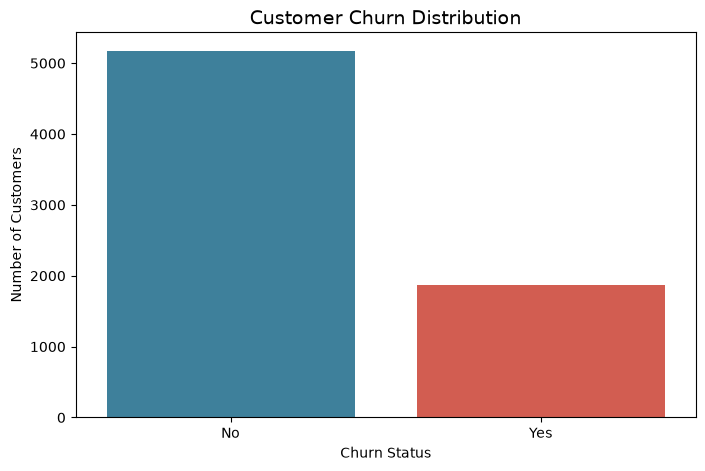

In [5]:
# Calculate churn distribution
churn_counts = df_clean['Churn'].value_counts()

# Calculate percentages
churn_percentages = df_clean['Churn'].value_counts(normalize=True) * 100

print("Churn Distribution:")
print(churn_counts)

print("\nChurn Percentages:")
print(churn_percentages.round(2))

# Visualization
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_clean,
    x='Churn',
    hue='Churn',
    palette=['#2E86AB', '#E74C3C'],
    legend=False
)

plt.title('Customer Churn Distribution', fontsize=14)
plt.xlabel('Churn Status')
plt.ylabel('Number of Customers')
plt.show()

Churn Rate by Contract:
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64


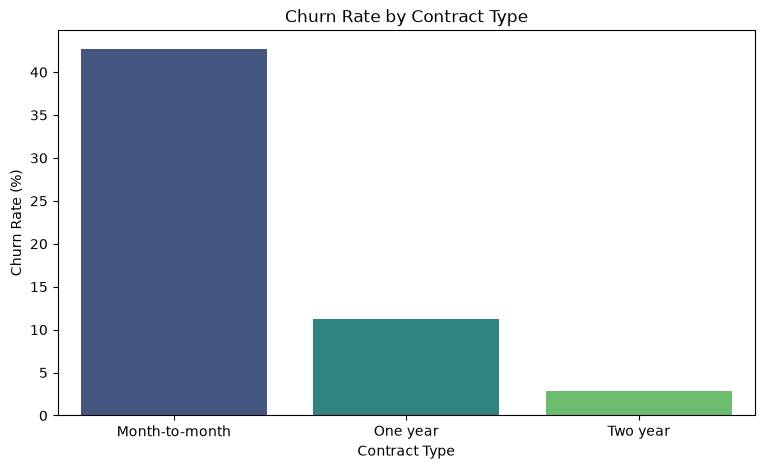

In [6]:
# Calculate churn rate by contract
contract_churn = (
    df_clean.groupby('Contract')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Contract:")
print(contract_churn.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    x=contract_churn.index,
    y=contract_churn.values,
    hue=contract_churn.index,
    palette='viridis',
    legend=False
)

plt.title('Churn Rate by Contract Type')
plt.xlabel('Contract Type')
plt.ylabel('Churn Rate (%)')
plt.show()

Churn Rate by Customer Tenure:
TenureGroup
0-12 months     47.44
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn, dtype: float64


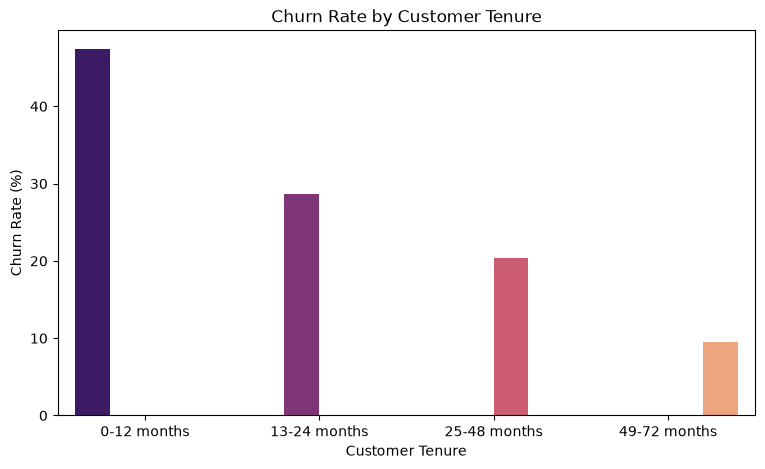

In [7]:
# Create customer tenure groups
df_clean['TenureGroup'] = pd.cut(
    df_clean['tenure'],
    bins=[-1, 12, 24, 48, 72],
    labels=['0-12 months', '13-24 months',
            '25-48 months', '49-72 months']
)

# Calculate churn rate
tenure_churn = (
    df_clean.groupby('TenureGroup', observed=False)['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
)

print("Churn Rate by Customer Tenure:")
print(tenure_churn.round(2))

# Visualization
plt.figure(figsize=(9, 5))

sns.barplot(
    x=tenure_churn.index,
    y=tenure_churn.values,
    hue=tenure_churn.index,
    palette='magma',
    legend=False
)

plt.title('Churn Rate by Customer Tenure')
plt.xlabel('Customer Tenure')
plt.ylabel('Churn Rate (%)')
plt.show()

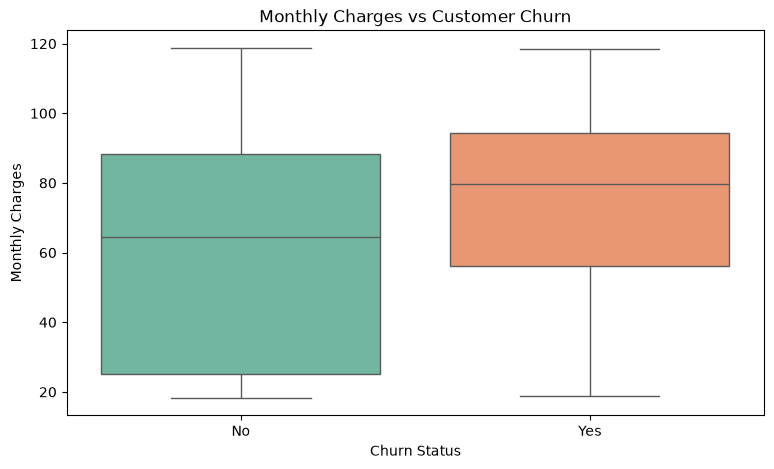

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [8]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x='Churn',
    y='MonthlyCharges',
    hue='Churn',
    palette='Set2',
    legend=False
)

plt.title('Monthly Charges vs Customer Churn')
plt.xlabel('Churn Status')
plt.ylabel('Monthly Charges')
plt.show()

# Compare average monthly charges
print(
    df_clean.groupby('Churn')['MonthlyCharges']
    .mean()
    .round(2)
)

Churn Rate by Payment Method:
PaymentMethod
Electronic check             45.29
Mailed check                 19.11
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Name: Churn, dtype: float64


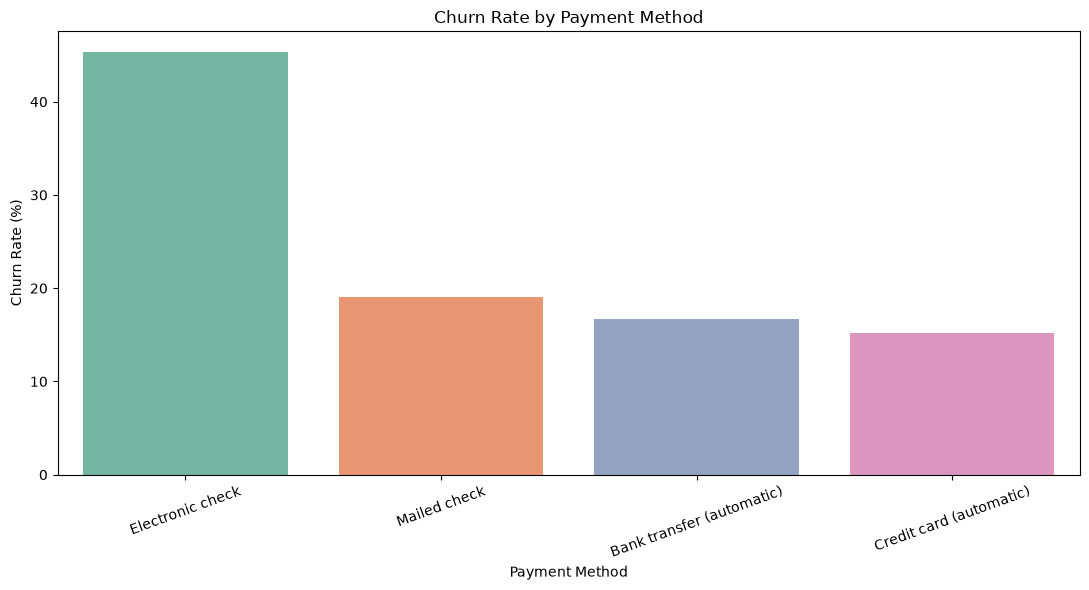

In [9]:
# Calculate churn rate by payment method

payment_churn = (
    df_clean.groupby('PaymentMethod')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Payment Method:")
print(payment_churn.round(2))

# Visualization

plt.figure(figsize=(11, 6))

sns.barplot(
    x=payment_churn.index,
    y=payment_churn.values,
    hue=payment_churn.index,
    palette='Set2',
    legend=False
)

plt.title('Churn Rate by Payment Method')
plt.xlabel('Payment Method')
plt.ylabel('Churn Rate (%)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [10]:
# Calculate churn rate by Internet Service

internet_churn = (
    df_clean.groupby('InternetService')['Churn']
    .apply(lambda x: (x == 'Yes').mean() * 100)
    .sort_values(ascending=False)
)

print("Churn Rate by Internet Service:")
print(internet_churn.round(2))

Churn Rate by Internet Service:
InternetService
Fiber optic    41.89
DSL            18.96
No              7.40
Name: Churn, dtype: float64


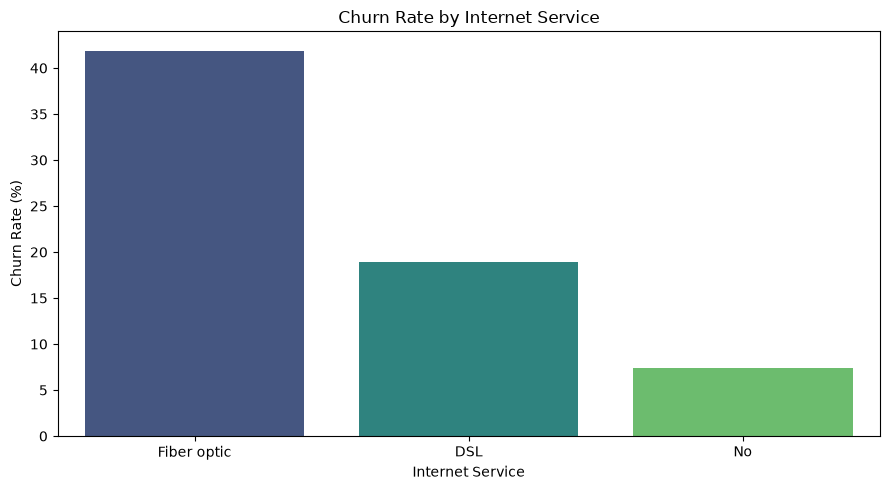

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values,
    hue=internet_churn.index,
    palette='viridis',
    legend=False
)

plt.title('Churn Rate by Internet Service')
plt.xlabel('Internet Service')
plt.ylabel('Churn Rate (%)')

plt.tight_layout()
plt.show()

In [12]:
# Separate features and target

X = df_clean.drop(
    columns=['customerID', 'Churn', 'TenureGroup'],
    errors='ignore'
)

y = df_clean['Churn'].map({
    'No': 0,
    'Yes': 1
})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Features shape: (7043, 19)
Target shape: (7043,)

Target distribution:
Churn
0    5174
1    1869
Name: count, dtype: int64


In [13]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X.select_dtypes(
    include=['object', 'str', 'category']
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [14]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (5634, 19)
Testing set: (1409, 19)

Training target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64

Testing target distribution:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [16]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [17]:
log_reg_model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(
        max_iter=1000,
        class_weight='balanced',
        random_state=42
    ))
])

In [18]:
log_reg_model.fit(X_train, y_train)

print("Model training completed successfully!")

Model training completed successfully!


In [19]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

models = {
    "Logistic Regression": log_reg_model,
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200, class_weight="balanced", random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ]),
}

results = []
for name, model in models.items():
    recall = cross_val_score(model, X_train, y_train, cv=5, scoring="recall").mean()
    auc = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc").mean()
    results.append({"Modèle": name, "Recall (CV)": round(recall, 3), "ROC-AUC (CV)": round(auc, 3)})

pd.DataFrame(results)

,Modèle,Recall (CV),ROC-AUC (CV)
0,Logistic Regression,0.804,0.845
1,Random Forest,0.645,0.825
2,Gradient Boosting,0.528,0.847


In [20]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
import pandas as pd

models = {
    "Logistic Regression": log_reg_model,
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200, class_weight="balanced", random_state=42))
    ]),
    "Gradient Boosting": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", GradientBoostingClassifier(random_state=42))
    ]),
}

results = []
for name, model in models.items():
    recall = cross_val_score(model, X_train, y_train, cv=5, scoring="recall").mean()
    auc = cross_val_score(model, X_train, y_train, cv=5, scoring="roc_auc").mean()
    results.append({"Modèle": name, "Recall (CV)": round(recall, 3), "ROC-AUC (CV)": round(auc, 3)})

pd.DataFrame(results)

,Modèle,Recall (CV),ROC-AUC (CV)
0,Logistic Regression,0.804,0.845
1,Random Forest,0.645,0.825
2,Gradient Boosting,0.528,0.847


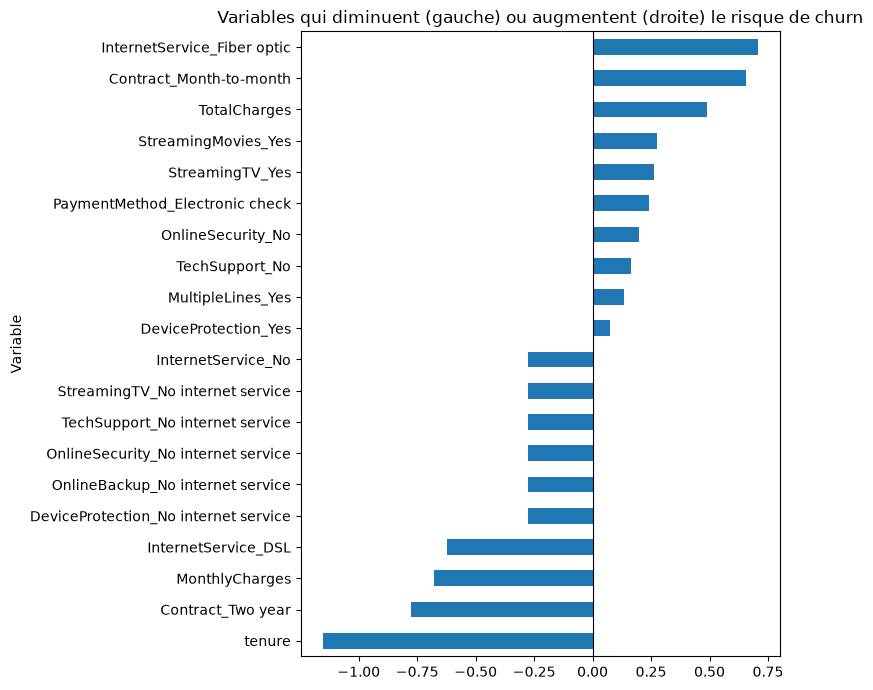

In [21]:
import pandas as pd
import matplotlib.pyplot as plt
feature_names = log_reg_model.named_steps["preprocessor"].get_feature_names_out()
coefs = log_reg_model.named_steps["classifier"].coef_[0]

coef_df = pd.DataFrame({"Variable": feature_names, "Coefficient": coefs})
coef_df["Variable"] = (coef_df["Variable"]
                       .str.replace("num__", "", regex=False)
                       .str.replace("cat__", "", regex=False))
coef_df = coef_df.sort_values("Coefficient")

top = pd.concat([coef_df.head(10), coef_df.tail(10)])
top.plot(kind="barh", x="Variable", y="Coefficient", legend=False, figsize=(8, 7))
plt.title("Variables qui diminuent (gauche) ou augmentent (droite) le risque de churn")
plt.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [22]:
import joblib

joblib.dump(log_reg_model, "churn_model.joblib")
joblib.dump(list(X_train.columns), "model_columns.joblib")
print("Modèle et colonnes sauvegardés !")

Modèle et colonnes sauvegardés !


In [23]:
df_clean.drop(columns=["TenureGroup"], errors="ignore").to_csv("telco_clean.csv", index=False)
print("telco_clean.csv sauvegardé !")

telco_clean.csv sauvegardé !


In [24]:
import os
print(os.getcwd())
os.listdir()

C:\Users\user


['.anaconda',
 '.anaconda-desktop',
 '.conda',
 '.config',
 '.continuum',
 '.copilot',
 '.docker',
 '.ipynb_checkpoints',
 '.ipython',
 '.jupyter',
 '.local',
 '.mamba',
 '.matplotlib',
 '.mchp_packs',
 '.mplabcomm',
 '.packettracer',
 '.streamlit',
 '.vscode',
 '.vscode-shared',
 '3D Objects',
 'anaconda3',
 'anaconda_projects',
 'AppData',
 'Application Data',
 'basevente.sql',
 'basevente1.sql',
 'basevente2.sql',
 'basevente3.sql',
 'basevente~1.sql',
 'basevente~2.sql',
 'basevente~21.sql',
 'basevente~3.sql',
 'basevente~31.sql',
 'basevente~4.sql',
 'basevente~41.sql',
 'basevente~5.sql',
 'basevente~6.sql',
 'basevente~7.sql',
 'basevente~8.sql',
 'battery-report.html',
 'churn.db',
 'churn_model.joblib',
 'Cisco Packet Tracer 9.0.1',
 'clients.sql',
 'Contacts',
 'Cookies',
 'Customer_Churn_Analysis.ipynb',
 'descente_gradient.png',
 'Desktop',
 'Documents',
 'Downloads',
 'FATIMAZAHRABOUZZAIT-1b-CR-AN TP2.pdf',
 'Favorites',
 'IntelGraphicsProfiles',
 'Links',
 'Local Setting

In [25]:
import os
os.listdir()

['.anaconda',
 '.anaconda-desktop',
 '.conda',
 '.config',
 '.continuum',
 '.copilot',
 '.docker',
 '.ipynb_checkpoints',
 '.ipython',
 '.jupyter',
 '.local',
 '.mamba',
 '.matplotlib',
 '.mchp_packs',
 '.mplabcomm',
 '.packettracer',
 '.streamlit',
 '.vscode',
 '.vscode-shared',
 '3D Objects',
 'anaconda3',
 'anaconda_projects',
 'AppData',
 'Application Data',
 'basevente.sql',
 'basevente1.sql',
 'basevente2.sql',
 'basevente3.sql',
 'basevente~1.sql',
 'basevente~2.sql',
 'basevente~21.sql',
 'basevente~3.sql',
 'basevente~31.sql',
 'basevente~4.sql',
 'basevente~41.sql',
 'basevente~5.sql',
 'basevente~6.sql',
 'basevente~7.sql',
 'basevente~8.sql',
 'battery-report.html',
 'churn.db',
 'churn_model.joblib',
 'Cisco Packet Tracer 9.0.1',
 'clients.sql',
 'Contacts',
 'Cookies',
 'Customer_Churn_Analysis.ipynb',
 'descente_gradient.png',
 'Desktop',
 'Documents',
 'Downloads',
 'FATIMAZAHRABOUZZAIT-1b-CR-AN TP2.pdf',
 'Favorites',
 'IntelGraphicsProfiles',
 'Links',
 'Local Setting

In [26]:
import sqlite3
import pandas as pd

df_sql = pd.read_csv("telco_clean.csv")

conn = sqlite3.connect("churn.db")
df_sql.to_sql("customers", conn, if_exists="replace", index=False)

print("Base churn.db créée avec", len(df_sql), "clients")

Base churn.db créée avec 7043 clients


In [27]:
queries = {
    "1. Taux de churn global": """
        SELECT COUNT(*) AS total_clients,
               SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS clients_partis,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_churn
        FROM customers
    """,
    "2. Churn par type de contrat": """
        SELECT Contract,
               COUNT(*) AS nb_clients,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_churn
        FROM customers
        GROUP BY Contract
        ORDER BY taux_churn DESC
    """,
    "3. Churn par tranche d'ancienneté": """
        SELECT CASE WHEN tenure <= 12 THEN '1) 0-12 mois'
                    WHEN tenure <= 24 THEN '2) 13-24 mois'
                    WHEN tenure <= 48 THEN '3) 25-48 mois'
                    ELSE '4) 49-72 mois' END AS anciennete,
               COUNT(*) AS nb_clients,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_churn
        FROM customers
        GROUP BY anciennete
        ORDER BY anciennete
    """,
    "4. Charges mensuelles moyennes selon le churn": """
        SELECT Churn, ROUND(AVG(MonthlyCharges), 2) AS charges_mensuelles_moyennes
        FROM customers
        GROUP BY Churn
    """,
    "5. Segment à haut risque (mensuel + fibre + 12 mois max)": """
        SELECT COUNT(*) AS nb_clients,
               ROUND(100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) / COUNT(*), 1) AS taux_churn
        FROM customers
        WHERE Contract = 'Month-to-month'
          AND InternetService = 'Fiber optic'
          AND tenure <= 12
    """,
}

for title, query in queries.items():
    print(title)
    display(pd.read_sql(query, conn))
    print()

1. Taux de churn global


,total_clients,clients_partis,taux_churn
0,7043,1869,26.5



2. Churn par type de contrat


,Contract,nb_clients,taux_churn
0,Month-to-month,3875,42.7
1,One year,1473,11.3
2,Two year,1695,2.8



3. Churn par tranche d'ancienneté


,anciennete,nb_clients,taux_churn
0,1) 0-12 mois,2186,47.4
1,2) 13-24 mois,1024,28.7
2,3) 25-48 mois,1594,20.4
3,4) 49-72 mois,2239,9.5



4. Charges mensuelles moyennes selon le churn


,Churn,charges_mensuelles_moyennes
0,No,61.27
1,Yes,74.44



5. Segment à haut risque (mensuel + fibre + 12 mois max)


,nb_clients,taux_churn
0,916,70.2
